In [8]:
!uv pip install --python C:\Users\s\.venv\Scripts\python.exe ccxt --force-reinstall

Using Python 3.14.0 environment at: C:\Users\s\.venv
Resolved 22 packages in 2.03s
Prepared 22 packages in 103ms
Uninstalled 22 packages in 1.60s
Installed 22 packages in 1.33s
 ~ aiohappyeyeballs==2.7.1
 ~ aiohttp==3.14.5
 ~ aiohttp-fast-zlib==0.3.0
 ~ aiosignal==1.4.0
 ~ attrs==26.1.0
 ~ ccxt==4.5.92
 ~ certifi==2026.10.23
 ~ cffi==2.0.0
 ~ charset-normalizer==3.4.7
 ~ cryptography==50.0.2
 ~ frozenlist==1.8.0
 ~ idna==3.18
 ~ multidict==6.9.1
 ~ orjson==3.13.0
 ~ propcache==0.5.2
 ~ pycparser==3.0
 ~ requests==2.34.2
 ~ typing-extensions==4.16.0
 ~ urllib3==2.8.0
 ~ winloop==0.6.3
 ~ yarl==1.25.1
 ~ zlib-ng==1.0.0


In [22]:
!uv pip install torch

Using Python 3.14.0 environment at: C:\Users\s\.venv
Resolved 10 packages in 1.73s
Prepared 7 packages in 38.32s
Installed 7 packages in 8.41s
 + filelock==4.2.9
 + fsspec==2026.9.0
 + mpmath==1.3.0
 + networkx==3.7
 + setuptools==84.2.1
 + sympy==1.14.0
 + torch==2.15.0


In [2]:
import ccxt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from datetime import datetime, timedelta, timezone
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

print("Config initialisee.")

Config initialisee.


In [3]:
SYMBOL = "BTC/USDT"
TIMEFRAME = "1h"

LOOKBACK = 24      # 24h d'observation
HORIZON = 4        # Prediction pour les 4 prochaines heures
YEARS = 2

In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ModuleNotFoundError: No module named 'google'

## Collecte des donnees
on utilise ccxt pour communiquer avec Binance et recuperer(par lots) les donnes.

In [4]:
df = pd.read_csv('btc_usdt_1h.csv')

In [5]:
df = df.drop("Unnamed: 0", axis=1, errors='ignore')

In [6]:
df = df.drop_duplicates(subset="timestamp")
df = df.set_index("timestamp")
df = df.astype(float)

In [6]:
df.head()

,open,high,low,close,volume
timestamp,,,,,
2020-01-01 00:00:00+00:00,7195.24,7196.25,7175.46,7177.02,511.814901
2020-01-01 01:00:00+00:00,7176.47,7230.00,7175.71,7216.27,883.052603
2020-01-01 02:00:00+00:00,7215.52,7244.87,7211.41,7242.85,655.156809
2020-01-01 03:00:00+00:00,7242.66,7245.00,7220.00,7225.01,783.724867
2020-01-01 04:00:00+00:00,7225.00,7230.00,7215.03,7217.27,467.812578


In [7]:
print("Informations générales :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum())

print("\nStatistiques descriptives :")
display(df.describe())

print("\nPériode couverte :")
print("Début :", df.index.min())
print("Fin :", df.index.max())

print("\nDoublons :", df.index.duplicated().sum())

Informations générales :
<class 'pandas.DataFrame'>
Index: 59966 entries, 2020-01-01 00:00:00+00:00 to 2026-11-04 21:00:00+00:00
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    59966 non-null  float64
 1   high    59966 non-null  float64
 2   low     59966 non-null  float64
 3   close   59966 non-null  float64
 4   volume  59966 non-null  float64
dtypes: float64(5)
memory usage: 2.7+ MB

Valeurs manquantes :
open      0
high      0
low       0
close     0
volume    0
dtype: int64

Statistiques descriptives :


,open,high,low,close,volume
count,59966.000000,59966.000000,59966.000000,59966.000000,59966.000000
mean,50488.722311,50678.719582,50290.294592,50489.938556,2792.551876
std,30884.601124,30967.211038,30799.344073,30884.332084,4247.938694
min,4131.230000,4610.000000,3782.130000,4130.640000,0.000000
25%,24314.392500,24437.932500,24164.517500,24317.990000,704.489127
50%,44788.345000,45051.215000,44500.000000,44789.845000,1426.938985
75%,69975.110000,70274.605000,69672.400000,69981.057500,2987.112147
max,126011.180000,126199.630000,125252.740000,126011.180000,137207.188600



Période couverte :
Début : 2020-01-01 00:00:00+00:00
Fin : 2026-11-04 21:00:00+00:00

Doublons : 0


In [7]:
df.index = pd.to_datetime(df.index).tz_localize(None)

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="1h"
).tz_localize(None)

missing = expected_index.difference(df.index)

print("Nombre d'heures manquantes :", len(missing))

Nombre d'heures manquantes : 32


In [8]:
df = df.reindex(expected_index)
df.ffill(inplace=True)

print("Nouveau nombre de lignes :", len(df))
print("Nombre de valeurs manquantes restantes :", df.isnull().sum().sum())


Nouveau nombre de lignes : 59998
Nombre de valeurs manquantes restantes : 0


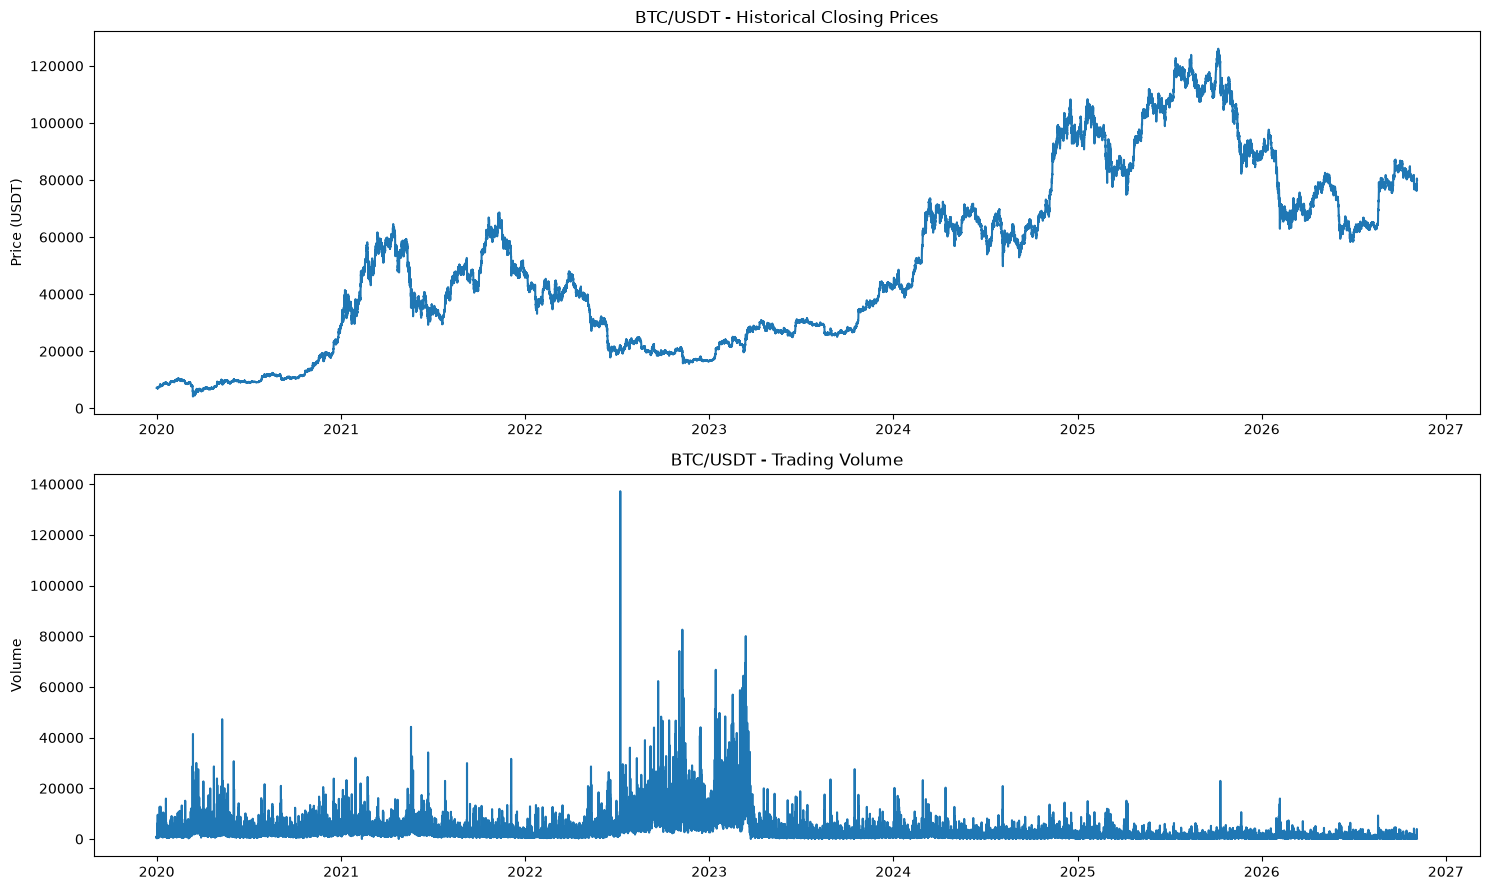

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(df.index, df["close"])
axes[0].set_title("BTC/USDT - Historical Closing Prices")
axes[0].set_ylabel("Price (USDT)")

axes[1].plot(df.index, df["volume"])
axes[1].set_title("BTC/USDT - Trading Volume")
axes[1].set_ylabel("Volume")

plt.tight_layout()
plt.show()

# Exploration et Pretraitement
transformer les données brutes en données exploitables par notre réseau neuronal.

## Calcul des variables financieres

In [9]:
# Rendement logarithmique, traduit les mouvements en variations de pourcentages comparables
df["log_return"] = np.log(
    df["close"] / df["close"].shift(1)
)

# Amplitude de la bougie
df["high_low_range"] = (
    (df["high"] - df["low"]) / df["close"]
)

# Variation entre ouverture et clôture, permet au modèle de connaître la direction pure (hausse ou baisse) et la force du mouvement sur cette heure précise.
df["open_close_return"] = (
    (df["close"] - df["open"]) / df["open"]
)

# Volume logarithmique
df["log_volume"] = np.log1p(df["volume"])

# Variation du volume
df["volume_change"] = df["log_volume"].diff()

# Volatilité historique sur 24 heures
df["historical_volatility"] = (
    df["log_return"].rolling(24).std(ddof=0)
)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

display(df.head())

,open,high,low,close,volume,log_return,high_low_range,open_close_return,log_volume,volume_change,historical_volatility
2020-01-02 00:00:00,7200.77,7212.50,7185.46,7211.02,391.352377,0.001411,0.003750,0.001423,5.972160,-0.727648,0.002199
2020-01-02 01:00:00,7211.04,7211.16,7185.11,7190.99,402.660139,-0.002782,0.003623,-0.002780,6.000573,0.028413,0.001984
2020-01-02 02:00:00,7190.99,7191.00,7155.35,7169.02,1387.377886,-0.003060,0.004973,-0.003055,7.235891,1.235318,0.001898
2020-01-02 03:00:00,7169.04,7169.06,7120.37,7129.61,1557.964430,-0.005512,0.006829,-0.005500,7.351777,0.115886,0.002119
2020-01-02 04:00:00,7129.25,7161.00,7116.70,7142.21,1252.447877,0.001766,0.006203,0.001818,7.133653,-0.218124,0.002166


## Creation de la cible: la volatilite future

In [10]:
future_returns = df["log_return"].shift(-1)

df["future_volatility"] = (
    future_returns
    .rolling(HORIZON)
    .std(ddof=0)
    .shift(-(HORIZON - 1))
)

df = df.dropna()

## Les trois regimes
- 0 : faible volatilite
- 1 : volatilite moyenne
- 2 : forte volatilite

In [11]:
# Séparation chronologique : 70 % / 15 % / 15 %

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))

Train : 41979
Validation : 8995
Test : 8996


Calcul des seuils uniquement sur l'entrainement

In [12]:
q33 = train_df["future_volatility"].quantile(0.33)
q66 = train_df["future_volatility"].quantile(0.66)

print("Seuil faible/moyen :", q33)
print("Seuil moyen/élevé :", q66)

Seuil faible/moyen : 0.002380137054400312
Seuil moyen/élevé : 0.004640607397065384


Creation des labels

In [13]:
def classify_regime(volatility):
    if volatility <= q33:
        return 0
    elif volatility <= q66:
        return 1
    else:
        return 2


df["market_regime"] = (
    df["future_volatility"].apply(classify_regime)
)

df["market_regime"] = df["market_regime"].astype(int)

print(df["market_regime"].value_counts())

market_regime
0    22347
1    19887
2    17736
Name: count, dtype: int64


Les variables d'entree

In [14]:
FEATURES = [
    "log_return",
    "high_low_range",
    "open_close_return",
    "log_volume",
    "volume_change",
    "historical_volatility"
]

TARGET_REGRESSION = "future_volatility"
TARGET_CLASSIFICATION = "market_regime"

X = df[FEATURES]

y_volatility = df[TARGET_REGRESSION]
y_regime = df[TARGET_CLASSIFICATION]

Normalisation des données

In [15]:
scaler = StandardScaler()

scaler.fit(X.iloc[:train_end])

X_scaled = scaler.transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=FEATURES,
    index=df.index
)

display(X_scaled.head())

,log_return,high_low_range,open_close_return,log_volume,volume_change,historical_volatility
2020-01-02 00:00:00,0.191220,-0.624820,0.189460,-1.784213,-1.484202,-0.902728
2020-01-02 01:00:00,-0.399136,-0.639227,-0.403909,-1.754708,0.057952,-0.957496
2020-01-02 02:00:00,-0.438324,-0.486330,-0.442689,-0.471924,2.519703,-0.979404
2020-01-02 03:00:00,-0.783639,-0.276100,-0.787768,-0.351585,0.236372,-0.923096
2020-01-02 04:00:00,0.241116,-0.347069,0.245129,-0.578090,-0.444914,-0.911267


Creation des sequences temporelles



In [16]:
X_sequences = []
y_vol_sequences = []
y_regime_sequences = []
target_indices = []

for i in range(LOOKBACK - 1, len(df)):

    sequence = X_scaled.iloc[
        i - LOOKBACK + 1 : i + 1
    ].values

    X_sequences.append(sequence)

    y_vol_sequences.append(
        y_volatility.iloc[i]
    )

    y_regime_sequences.append(
        y_regime.iloc[i]
    )

    target_indices.append(i)


X_sequences = np.array(X_sequences, dtype=np.float32)

y_vol_sequences = np.array(
    y_vol_sequences, dtype=np.float32
)

y_regime_sequences = np.array(
    y_regime_sequences, dtype=np.int64
)

target_indices = np.array(target_indices)

print("Shape X :", X_sequences.shape)
print("Shape volatilité :", y_vol_sequences.shape)
print("Shape régime :", y_regime_sequences.shape)

Shape X : (59947, 24, 6)
Shape volatilité : (59947,)
Shape régime : (59947,)


Separation des sequences

In [17]:
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

y_vol_train = y_vol_sequences[train_mask]
y_vol_val = y_vol_sequences[val_mask]
y_vol_test = y_vol_sequences[test_mask]

y_regime_train = y_regime_sequences[train_mask]
y_regime_val = y_regime_sequences[val_mask]
y_regime_test = y_regime_sequences[test_mask]

print("TRAIN :", X_train.shape)
print("VALIDATION :", X_val.shape)
print("TEST :", X_test.shape)

TRAIN : (41956, 24, 6)
VALIDATION : (8995, 24, 6)
TEST : (8996, 24, 6)


In [18]:
print("===== DATASET FINAL =====")

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("\n===== DISTRIBUTION DES RÉGIMES =====")

for name, labels in [
    ("Train", y_regime_train),
    ("Validation", y_regime_val),
    ("Test", y_regime_test)
]:
    print(f"\n{name}")
    print(pd.Series(labels).value_counts(normalize=True).sort_index())

print("\n===== VOLATILITÉ =====")

print("Train :", y_vol_train.min(), y_vol_train.max())
print("Validation :", y_vol_val.min(), y_vol_val.max())
print("Test :", y_vol_test.min(), y_vol_test.max())

===== DATASET FINAL =====
X_train : (41956, 24, 6)
X_val   : (8995, 24, 6)
X_test  : (8996, 24, 6)

===== DISTRIBUTION DES RÉGIMES =====

Train
0    0.330108
1    0.329822
2    0.340071
Name: proportion, dtype: float64

Validation
0    0.465147
1    0.335186
2    0.199666
Name: proportion, dtype: float64

Test
0    0.479102
1    0.335594
2    0.185305
Name: proportion, dtype: float64

===== VOLATILITÉ =====
Train : 0.0 0.13117397
Validation : 7.9849575e-05 0.029397571
Test : 9.1221285e-05 0.025715055


# Construction et entraînement du modèle LSTM

In [19]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

import copy
import random

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)


In [30]:

# Reproductibilité
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device :", device)

Device : cpu


## Préparation des cibles

In [31]:
EPSILON = 1e-10

# Transformation logarithmique
y_vol_train_log = np.log(y_vol_train + EPSILON)
y_vol_val_log = np.log(y_vol_val + EPSILON)
y_vol_test_log = np.log(y_vol_test + EPSILON)

# Paramètres calculés uniquement sur le train
vol_mean = y_vol_train_log.mean()
vol_std = y_vol_train_log.std()

# Standardisation
y_vol_train_scaled = (
    (y_vol_train_log - vol_mean) / vol_std
)

y_vol_val_scaled = (
    (y_vol_val_log - vol_mean) / vol_std
)

y_vol_test_scaled = (
    (y_vol_test_log - vol_mean) / vol_std
)

print("Mean :", vol_mean)
print("Std :", vol_std)

Mean : -5.7231607
Std : 0.82625854


In [32]:
BATCH_SIZE = 256

def create_loader(X, y_vol, y_regime, shuffle=False):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y_vol, dtype=torch.float32),
        torch.tensor(y_regime, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


train_loader = create_loader(
    X_train,
    y_vol_train_scaled,
    y_regime_train,
    shuffle=True
)

val_loader = create_loader(
    X_val,
    y_vol_val_scaled,
    y_regime_val
)

test_loader = create_loader(
    X_test,
    y_vol_test_scaled,
    y_regime_test
)

print("Nombre de batchs train :", len(train_loader))
print("Nombre de batchs validation :", len(val_loader))
print("Nombre de batchs test :", len(test_loader))

Nombre de batchs train : 164
Nombre de batchs validation : 36
Nombre de batchs test : 36


Architecture du modele LSTM

In [33]:
class LSTMModel(nn.Module):

    def __init__(
        self,
        input_size=6,
        hidden_size=64,
        num_layers=2,
        dropout=0.3,
        num_classes=3
    ):

        super().__init__()

        # Réseau LSTM partagé
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Représentation commune
        self.shared = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Tête de régression
        self.volatility_head = nn.Linear(32, 1)

        # Tête de classification
        self.regime_head = nn.Linear(32, num_classes)

    def forward(self, x):

        lstm_output, (hidden, cell) = self.lstm(x)

        # Dernière observation temporelle
        last_output = lstm_output[:, -1, :]

        shared_output = self.shared(last_output)

        volatility = self.volatility_head(
            shared_output
        ).squeeze(1)

        regime = self.regime_head(shared_output)

        return volatility, regime

In [34]:
model = LSTMModel(
    input_size=6,
    hidden_size=64,
    num_layers=2,
    dropout=0.3,
    num_classes=3
).to(device)

print(model)

LSTMModel(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.3)
  (shared): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (volatility_head): Linear(in_features=32, out_features=1, bias=True)
  (regime_head): Linear(in_features=32, out_features=3, bias=True)
)


## Fonction de perte er optimisateur

In [35]:
regression_loss = nn.SmoothL1Loss()

classification_loss = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

LAMBDA_VOL = 1.0
LAMBDA_REGIME = 1.0

## Fonction d'entrainement

In [36]:
def train_one_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0
    total_vol_loss = 0
    total_regime_loss = 0

    for X_batch, y_vol_batch, y_regime_batch in loader:

        X_batch = X_batch.to(device)
        y_vol_batch = y_vol_batch.to(device)
        y_regime_batch = y_regime_batch.to(device)

        optimizer.zero_grad()

        # Prédictions
        pred_vol, pred_regime = model(X_batch)

        # Calcul des pertes
        loss_vol = regression_loss(
            pred_vol, y_vol_batch
        )

        loss_regime = classification_loss(
            pred_regime, y_regime_batch
        )

        loss = (
            LAMBDA_VOL * loss_vol +
            LAMBDA_REGIME * loss_regime
        )

        # Backpropagation
        loss.backward()

        # Limitation des gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()
        total_vol_loss += loss_vol.item()
        total_regime_loss += loss_regime.item()

    n = len(loader)

    return (
        total_loss / n,
        total_vol_loss / n,
        total_regime_loss / n
    )

## Fonction de validation

In [26]:
def validate(model, loader):

    model.eval()

    total_loss = 0
    total_vol_loss = 0
    total_regime_loss = 0

    with torch.no_grad():

        for X_batch, y_vol_batch, y_regime_batch in loader:

            X_batch = X_batch.to(device)
            y_vol_batch = y_vol_batch.to(device)
            y_regime_batch = y_regime_batch.to(device)

            pred_vol, pred_regime = model(X_batch)

            loss_vol = regression_loss(
                pred_vol, y_vol_batch
            )

            loss_regime = classification_loss(
                pred_regime, y_regime_batch
            )

            loss = (
                LAMBDA_VOL * loss_vol +
                LAMBDA_REGIME * loss_regime
            )

            total_loss += loss.item()
            total_vol_loss += loss_vol.item()
            total_regime_loss += loss_regime.item()

    n = len(loader)

    return (
        total_loss / n,
        total_vol_loss / n,
        total_regime_loss / n
    )

## **Entrainement du model**

In [27]:
EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_vol_loss": [],
    "val_vol_loss": [],
    "train_regime_loss": [],
    "val_regime_loss": []
}

for epoch in range(EPOCHS):

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_metrics = validate(
        model,
        val_loader
    )

    train_loss, train_vol, train_regime = train_metrics
    val_loss, val_vol, val_regime = val_metrics

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_vol_loss"].append(train_vol)
    history["val_vol_loss"].append(val_vol)

    history["train_regime_loss"].append(train_regime)
    history["val_regime_loss"].append(val_regime)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train: {train_loss:.5f} "
        f"| Val: {val_loss:.5f} "
        f"| Vol: {val_vol:.5f} "
        f"| Regime: {val_regime:.5f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_state,
            "best_lstm_model.pth"
        )

        patience_counter = 0

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping déclenché.")
        break


# Restaurer les meilleurs paramètres
model.load_state_dict(best_model_state)

print("\nMeilleur modèle restauré.")

NameError: name 'model' is not defined

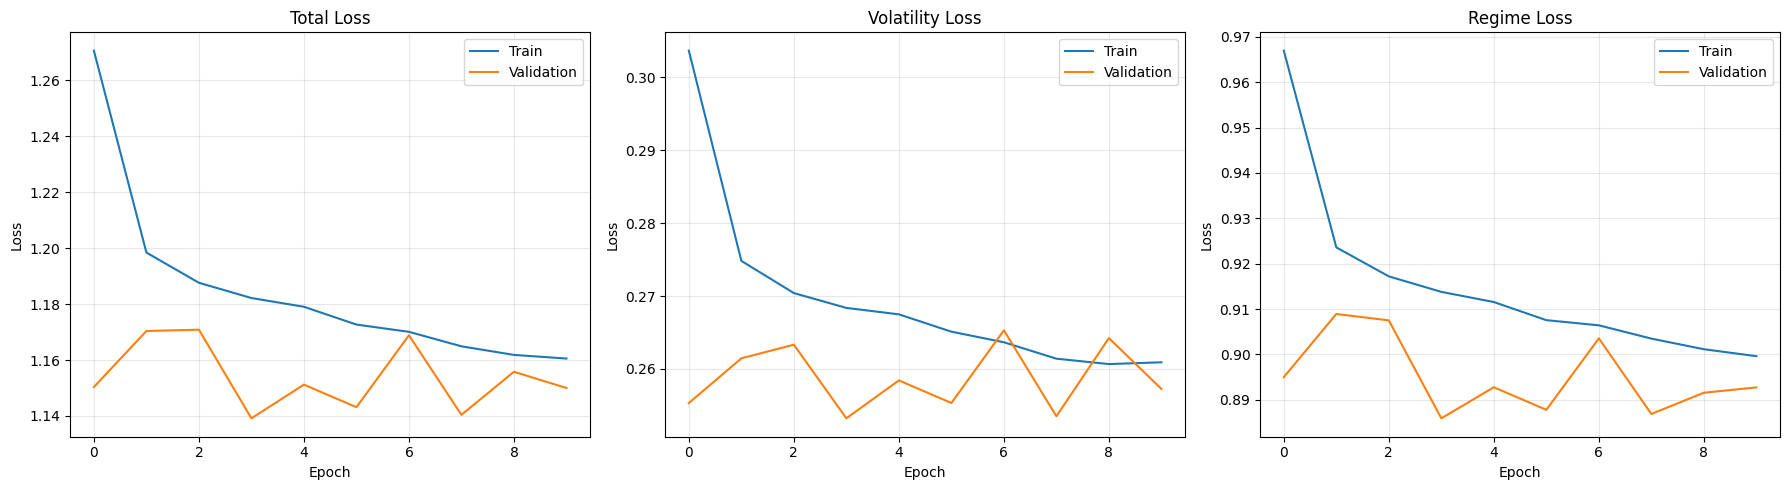

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Total Loss")

axes[1].plot(history["train_vol_loss"], label="Train")
axes[1].plot(history["val_vol_loss"], label="Validation")
axes[1].set_title("Volatility Loss")

axes[2].plot(history["train_regime_loss"], label="Train")
axes[2].plot(history["val_regime_loss"], label="Validation")
axes[2].set_title("Regime Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Trouver la valeur minimale de la val_loss globale
best_val_loss = min(history['val_loss'])

# 2. Trouver l'époque correspondante (on ajoute +1 car l'indexation commence à 0)
best_epoch = history['val_loss'].index(best_val_loss) + 1

print(f"La meilleure val_loss globale est : {best_val_loss:.4f}")
print(f"Elle a été atteinte à l'Époque : {best_epoch}")


La meilleure val_loss globale est : 1.1392
Elle a été atteinte à l'Époque : 4


Évaluation sur la validation

In [31]:
def get_predictions(model, loader):

    model.eval()

    predictions_vol = []
    predictions_regime = []
    actual_regime = []

    with torch.no_grad():

        for X_batch, y_vol_batch, y_regime_batch in loader:

            X_batch = X_batch.to(device)

            pred_vol, pred_regime = model(X_batch)

            predictions_vol.extend(
                pred_vol.cpu().numpy()
            )

            predictions_regime.extend(
                pred_regime.argmax(dim=1).cpu().numpy()
            )

            actual_regime.extend(
                y_regime_batch.numpy()
            )

    return (
        np.array(predictions_vol),
        np.array(predictions_regime),
        np.array(actual_regime)
    )


val_pred_vol_scaled, val_pred_regime, val_actual_regime = (
    get_predictions(model, val_loader)
)

# Retour à l'échelle originale
val_pred_vol = np.exp(
    val_pred_vol_scaled * vol_std + vol_mean
) - EPSILON

val_pred_vol = np.maximum(val_pred_vol, 0)

# Métriques de régression
val_mae = mean_absolute_error(
    y_vol_val, val_pred_vol
)

val_rmse = np.sqrt(
    mean_squared_error(y_vol_val, val_pred_vol)
)

print("===== VOLATILITY PREDICTION =====")
print("MAE :", val_mae)
print("RMSE :", val_rmse)

# Métriques de classification
val_accuracy = accuracy_score(
    val_actual_regime, val_pred_regime
)

val_f1 = f1_score(
    val_actual_regime,
    val_pred_regime,
    average="macro"
)

val_balanced_accuracy = balanced_accuracy_score(
    val_actual_regime,
    val_pred_regime
)

print("\n===== MARKET REGIME CLASSIFICATION =====")
print("Accuracy :", val_accuracy)
print("Macro F1 :", val_f1)
print("Balanced Accuracy :", val_balanced_accuracy)

print("\nClassification report :")

print(
    classification_report(
        val_actual_regime,
        val_pred_regime,
        labels=[0, 1, 2],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    )
)

===== VOLATILITY PREDICTION =====
MAE : 0.00199874397367239
RMSE : 0.0026817023328528544

===== MARKET REGIME CLASSIFICATION =====
Accuracy : 0.33518621456364645
Macro F1 : 0.16736053288925898
Balanced Accuracy : 0.3333333333333333

Classification report :
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00      4184
      Medium       0.34      1.00      0.50      3015
        High       0.00      0.00      0.00      1796

    accuracy                           0.34      8995
   macro avg       0.11      0.33      0.17      8995
weighted avg       0.11      0.34      0.17      8995



Evaluation sur la validation

In [21]:
def get_predictions(model, loader):

    model.eval()

    predictions_vol = []
    predictions_regime = []
    actual_regime = []

    with torch.no_grad():

        for X_batch, y_vol_batch, y_regime_batch in loader:

            X_batch = X_batch.to(device)

            pred_vol, pred_regime = model(X_batch)

            predictions_vol.extend(
                pred_vol.cpu().numpy()
            )

            predictions_regime.extend(
                pred_regime.argmax(dim=1).cpu().numpy()
            )

            actual_regime.extend(
                y_regime_batch.numpy()
            )

    return (
        np.array(predictions_vol),
        np.array(predictions_regime),
        np.array(actual_regime)
    )


val_pred_vol_scaled, val_pred_regime, val_actual_regime = (
    get_predictions(model, val_loader)
)

# Retour à l'échelle originale
val_pred_vol = np.exp(
    val_pred_vol_scaled * vol_std + vol_mean
) - EPSILON

val_pred_vol = np.maximum(val_pred_vol, 0)

# Métriques de régression
val_mae = mean_absolute_error(
    y_vol_val, val_pred_vol
)

val_rmse = np.sqrt(
    mean_squared_error(y_vol_val, val_pred_vol)
)

print("===== VOLATILITY PREDICTION =====")
print("MAE :", val_mae)
print("RMSE :", val_rmse)

# Métriques de classification
val_accuracy = accuracy_score(
    val_actual_regime, val_pred_regime
)

val_f1 = f1_score(
    val_actual_regime,
    val_pred_regime,
    average="macro"
)

val_balanced_accuracy = balanced_accuracy_score(
    val_actual_regime,
    val_pred_regime
)

print("\n===== MARKET REGIME CLASSIFICATION =====")
print("Accuracy :", val_accuracy)
print("Macro F1 :", val_f1)
print("Balanced Accuracy :", val_balanced_accuracy)

print("\nClassification report :")

print(
    classification_report(
        val_actual_regime,
        val_pred_regime,
        labels=[0, 1, 2],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    )
)

NameError: name 'model' is not defined

Matrice de confusion

In [20]:
cm = confusion_matrix(
    val_actual_regime,
    val_pred_regime,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("LSTM - Confusion Matrix")

plt.show()

NameError: name 'val_actual_regime' is not defined

Comparaison avec une reference simple

In [ ]:
# Baseline régression
baseline_vol = np.full(
    len(y_vol_val),
    y_vol_train.mean()
)

baseline_mae = mean_absolute_error(
    y_vol_val,
    baseline_vol
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_vol_val, baseline_vol)
)

# Baseline classification
majority_class = pd.Series(
    y_regime_train
).mode()[0]

baseline_regime = np.full(
    len(y_regime_val),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_regime_val,
    baseline_regime
)

baseline_f1 = f1_score(
    y_regime_val,
    baseline_regime,
    average="macro",
    zero_division=0
)

comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "Accuracy", "Macro F1"],
    "Baseline": [
        baseline_mae,
        baseline_rmse,
        baseline_accuracy,
        baseline_f1
    ],
    "LSTM": [
        val_mae,
        val_rmse,
        val_accuracy,
        val_f1
    ]
})

display(comparison)

,Metric,Baseline,LSTM
0,MAE,0.002383,0.001465
1,RMSE,0.002906,0.002331
2,Accuracy,0.199733,0.563278
3,Macro F1,0.110988,0.529535


# Evaluation sur le test set

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_vol_preds = []
all_regime_preds = []

with torch.no_grad():
    for X_batch, _, _ in test_loader:
        X_batch = X_batch.to(device)

        vol_output, regime_output = model(X_batch)

        all_vol_preds.extend(vol_output.cpu().numpy())
        all_regime_preds.extend(
            regime_output.argmax(dim=1).cpu().numpy()
        )

# Volatility predictions: inverse standardization + log
y_vol_pred_test = np.exp(
    np.array(all_vol_preds) * vol_std + vol_mean
) - EPSILON

y_vol_pred_test = np.maximum(y_vol_pred_test, 0)

# Regression metrics
mae_test = mean_absolute_error(y_vol_test, y_vol_pred_test)
rmse_test = np.sqrt(
    mean_squared_error(y_vol_test, y_vol_pred_test)
)

# Classification metrics
accuracy_test = accuracy_score(y_regime_test, all_regime_preds)
macro_f1_test = f1_score(
    y_regime_test, all_regime_preds, average="macro"
)
balanced_acc_test = balanced_accuracy_score(
    y_regime_test, all_regime_preds
)

print("===== FINAL TEST RESULTS =====")
print(f"MAE : {mae_test:.6f}")
print(f"RMSE : {rmse_test:.6f}")
print(f"Accuracy : {accuracy_test:.4f}")
print(f"Macro F1 : {macro_f1_test:.4f}")
print(f"Balanced Accuracy : {balanced_acc_test:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_regime_test,
    all_regime_preds,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"]
))

===== FINAL TEST RESULTS =====
MAE : 0.001406
RMSE : 0.002187
Accuracy : 0.5447
Macro F1 : 0.4968
Balanced Accuracy : 0.4886

Classification Report:
              precision    recall  f1-score   support

         Low       0.65      0.69      0.67      4303
      Medium       0.41      0.46      0.44      3022
        High       0.50      0.31      0.38      1667

    accuracy                           0.54      8992
   macro avg       0.52      0.49      0.50      8992
weighted avg       0.54      0.54      0.54      8992



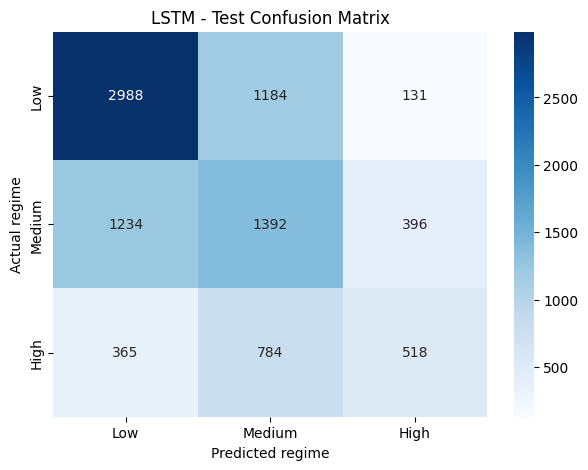

In [76]:
cm = confusion_matrix(
    y_regime_test,
    all_regime_preds,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("LSTM - Test Confusion Matrix")
plt.show()

# Fonction de prediction

In [33]:
def predict_market():

    # 1. Connect to Binance
    exchange = ccxt.binance({
        "enableRateLimit": True
    })

    # 2. Fetch recent OHLCV data
    candles = exchange.fetch_ohlcv(
        SYMBOL,
        timeframe=TIMEFRAME,
        limit=100
    )

    live_df = pd.DataFrame(
        candles,
        columns=[
            "timestamp", "open", "high",
            "low", "close", "volume"
        ]
    )

    live_df["timestamp"] = pd.to_datetime(
        live_df["timestamp"],
        unit="ms",
        utc=True
    )

    live_df = live_df.set_index("timestamp")

    # Remove incomplete candle
    now_ms = int(datetime.now(timezone.utc).timestamp() * 1000)

    live_df = live_df[
        (live_df.index.astype("int64") // 10**6 + 3600000)
        <= now_ms
    ]

    # 3. Feature engineering (same as training)
    live_df["log_return"] = np.log(
        live_df["close"] / live_df["close"].shift(1)
    )

    live_df["high_low_range"] = (
        live_df["high"] - live_df["low"]
    ) / live_df["close"]

    live_df["open_close_return"] = (
        live_df["close"] - live_df["open"]
    ) / live_df["open"]

    live_df["log_volume"] = np.log1p(live_df["volume"])

    live_df["volume_change"] = (
        live_df["log_volume"].diff()
    )

    live_df["historical_volatility"] = (
        live_df["log_return"]
        .rolling(24)
        .std(ddof=0)
    )

    live_df = live_df.replace(
        [np.inf, -np.inf], np.nan
    ).dropna(subset=FEATURES)

    # 4. Select the last 24 observations
    if len(live_df) < LOOKBACK:
        raise ValueError("Not enough data to make a prediction.")

    latest_data = live_df[FEATURES].tail(LOOKBACK)

    # 5. Apply the existing scaler
    X_live = scaler.transform(latest_data)

    X_live = torch.tensor(
        X_live,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # 6. LSTM prediction
    model.eval()

    with torch.no_grad():

        volatility_output, regime_output = model(X_live)

        # Inverse transformation of volatility
        volatility_z = volatility_output.item()

        predicted_volatility = (
            np.exp(volatility_z * vol_std + vol_mean)
            - EPSILON
        )

        predicted_volatility = max(
            predicted_volatility, 0
        )

        # Regime probabilities
        probabilities = torch.softmax(
            regime_output, dim=1
        ).cpu().numpy()[0]

    # 7. Identify predicted regime
    regime_names = ["Low", "Medium", "High"]

    predicted_regime = regime_names[
        np.argmax(probabilities)
    ]

    results = {
        "last_candle": latest_data.index[-1],
        "predicted_volatility": predicted_volatility,
        "predicted_volatility_percent": predicted_volatility * 100,
        "predicted_regime": predicted_regime,
        "probabilities": {
            regime_names[i]: float(probabilities[i])
            for i in range(3)
        }
    }

    return results

In [34]:
prediction = predict_market()

print("===== BTC/USDT MARKET PREDICTION =====")

print(f"Last candle: {prediction['last_candle']}")

print(
    f"\nPredicted volatility (next 4h): "
    f"{prediction['predicted_volatility_percent']:.4f}%"
)

print(
    f"Predicted market regime: "
    f"{prediction['predicted_regime']}"
)

print("\nRegime probabilities:")

for regime, probability in prediction["probabilities"].items():
    print(f"{regime}: {probability:.2%}")

===== BTC/USDT MARKET PREDICTION =====
Last candle: 2026-11-05 02:00:00+00:00

Predicted volatility (next 4h): 0.3720%
Predicted market regime: Medium

Regime probabilities:
Low: 29.90%
Medium: 40.90%
High: 29.20%


In [81]:
import torch
import numpy as np

checkpoint = {
    "model_state_dict": model.state_dict(),

    "scaler": {
        "mean": torch.tensor(scaler.mean_),
        "scale": torch.tensor(scaler.scale_),
        "var": torch.tensor(scaler.var_),
        "n_features_in": scaler.n_features_in_,
        "n_samples_seen": int(scaler.n_samples_seen_)
    },

    "vol_mean": float(vol_mean),
    "vol_std": float(vol_std),

    "features": FEATURES,
    "lookback": LOOKBACK,
    "horizon": HORIZON,

    "symbol": SYMBOL,
    "timeframe": TIMEFRAME,

    "q33": float(q33),
    "q66": float(q66),

    "model_config": {
        "input_size": len(FEATURES),
        "hidden_size": 64,
        "num_layers": 2,
        "dropout": 0.2
    }
}

torch.save(checkpoint, "crypto_lstm_checkpoint.pth")

print("Modèle et paramètres sauvegardés avec succès.")

Modèle et paramètres sauvegardés avec succès.


In [35]:
prediction = predict_market()
print(prediction)

{'last_candle': Timestamp('2026-11-05 02:00:00+0000', tz='UTC'), 'predicted_volatility': np.float32(0.003719907), 'predicted_volatility_percent': np.float32(0.3719907), 'predicted_regime': 'Medium', 'probabilities': {'Low': 0.2990100383758545, 'Medium': 0.4090195894241333, 'High': 0.2919703423976898}}


In [37]:
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params, trainable_params

total, trainable = count_parameters(model)
print(f"Nombre total de paramètres : {total:,}")
print(f"Nombre de paramètres entraînables : {trainable:,}")

Nombre total de paramètres : 53,924
Nombre de paramètres entraînables : 53,924
